BCOS estimates the probability that the carrier reaches a target location before defenders control it. The resulting field shows where the carrier has open space under the modeled motion assumptions. **own derivation**

## Model and inputs

The competing-risk solver tracks carrier arrival probability S and defender interception probabilities P_i at each target. At each time step, U=clip(1−S−Σ_i P_i,0,1); dS=U h_BC dt and dP_i=U h_i dt. Thus each defender contributes a cause-specific probability while competing through the shared remaining mass. The reported open-space field is carrier arrival probability at the integration horizon. Inputs include carrier/defender positions and velocities, a target grid, motion/rotation parameters, and numerical step settings. **own derivation**.

## Usage and visual

The contour is a clearly labeled toy illustration. For a real frame, the optional package API below computes and plots the BCOS field from canonical wide tracking data.

```python
import numpy as np
from PRESS.extras import BCOS
from PRESS.visualization import plot_bcos

bcos = BCOS(tracking_data)  # canonical wide tracking table
result = bcos.compute_bcos(frame_id)
bcos_value = float(np.asarray(result["Ball carrier open space"]).sum())
plot_bcos(bcos, frame_id)
```

## Component scope and model limits

The modeled concept is Ball Carrier Open Space (BCOS), a formalization inspired by Bandara et al. [@bandara2025bcos]. Competing-risk equations follow the implementation; **own derivation**.

This solver is a PRESS competing-risk formalization of carrier open space using tracked positions and velocities. It is inspired by the BCOS concept but does not reproduce Bandara et al.’s camera-visible-area calculation from event freeze frames. **own derivation; model scope**


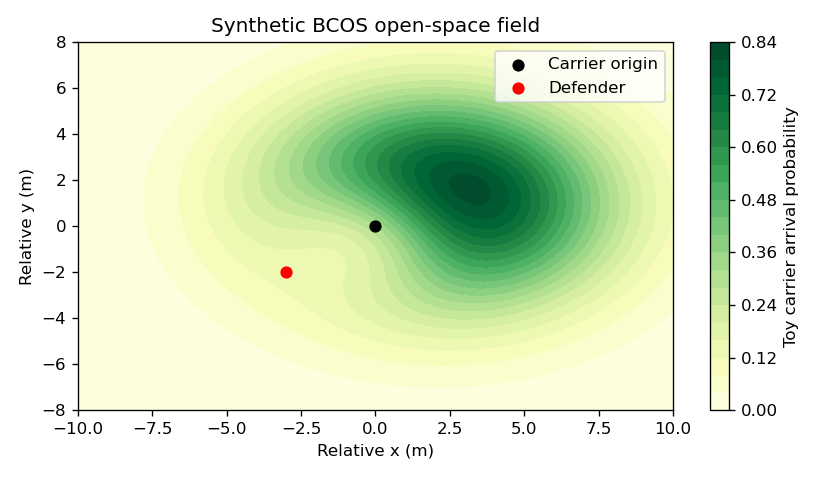

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
# Toy probability field demonstrating the output shape of BCOS.
x,y=np.meshgrid(np.linspace(-10,10,61),np.linspace(-8,8,49)); carrier=np.exp(-((x-2)**2/30+(y-1)**2/20)); defender=.72*np.exp(-((x+1)**2/15+(y+1)**2/12)); open_space=np.clip(carrier*(1-defender),0,1)
fig,ax=plt.subplots(figsize=(7,4)); im=ax.contourf(x,y,open_space,levels=20,cmap="YlGn"); fig.colorbar(im,ax=ax,label="Toy carrier arrival probability"); ax.scatter([0], [0], c="black",s=40,label="Carrier origin"); ax.scatter([-3],[-2],c="red",s=40,label="Defender"); ax.set(xlabel="Relative x (m)",ylabel="Relative y (m)",title="Synthetic BCOS open-space field"); ax.legend(); fig.tight_layout()
out=Path("figures/vignette_10_bcos.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../../usage.qmd) to use processed local files.


BCOS scalar input: 8.787792154591978
field size: 13


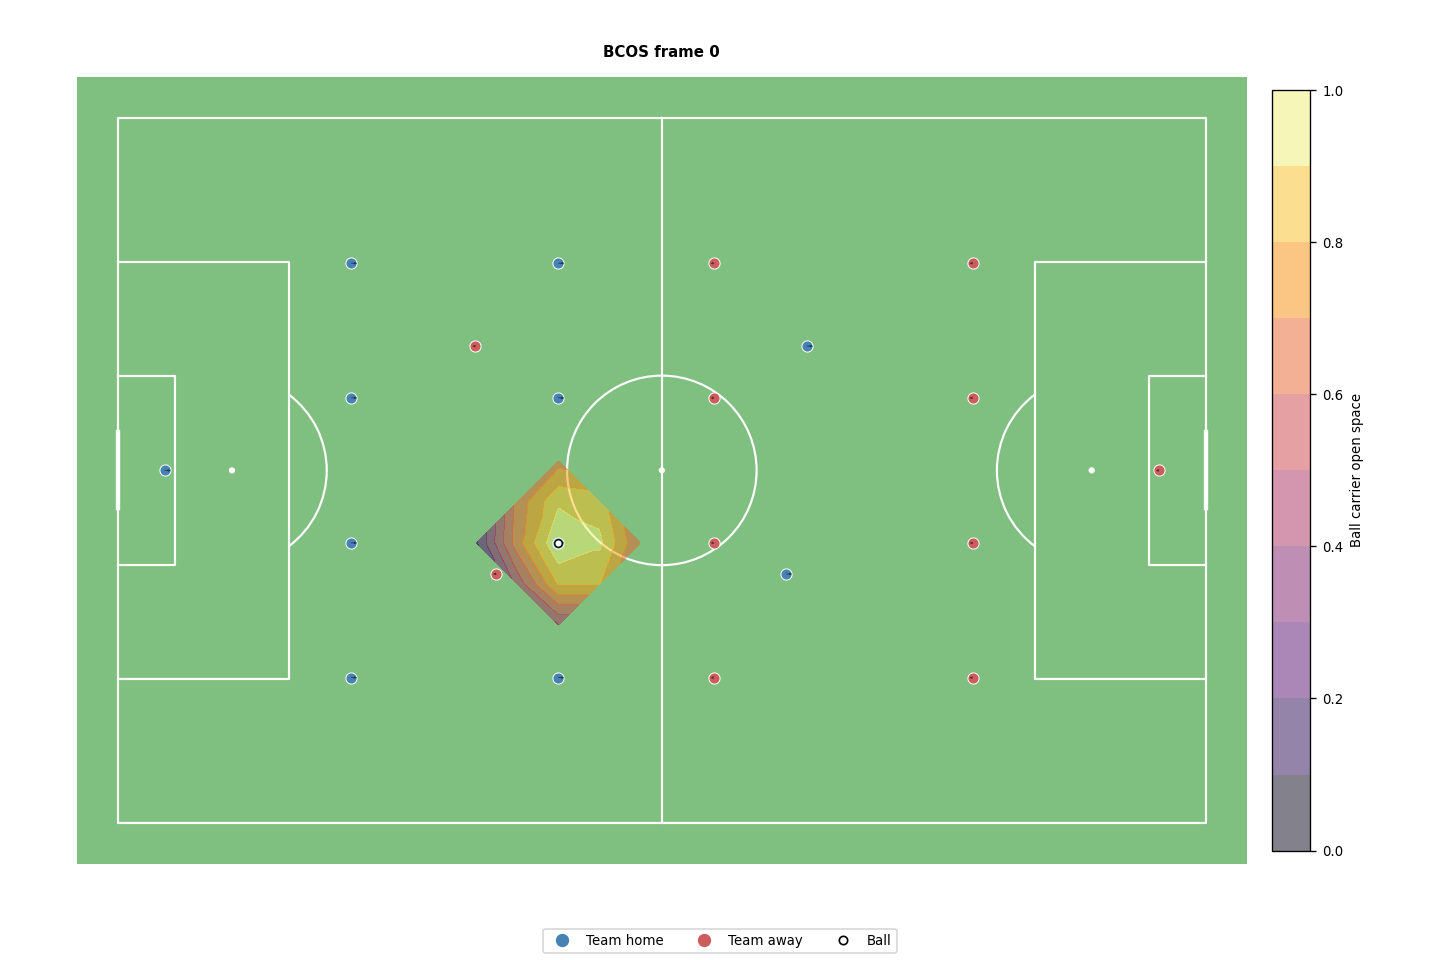

In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_checkpoints(possession_id).frame_id.iloc[0])
from PRESS.extras import BCOS
bcos = BCOS(tracking)
bcos_result = bcos.compute_bcos(frame_id, r_max=8, step=4)
bcos_value = float(np.asarray(bcos_result["Ball carrier open space"]).sum())
from PRESS.visualization import plot_bcos
print("BCOS scalar input:", bcos_value)
print("field size:", np.asarray(bcos.get_result(frame_id)["Ball carrier open space"]).size)
plot_bcos(bcos, frame_id)
